<a href="https://colab.research.google.com/github/bondiolandia/TP_Laboratorio_de_M-todos_Cuantitativos_2026/blob/main/notebook_Evolucion_del_Anime.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

# Carga y exploración inicial

In [3]:
# Importamos la libreria de Kaggle y el data set con el que vamos a trabajar
import kagglehub as kg
from kagglehub import KaggleDatasetAdapter

camino = "anime-dataset-2026.csv"
Datos = kg.dataset_load(KaggleDatasetAdapter.PANDAS,"darkbarrierhub/anime-dataset-2026",camino)

# Seleccionamos una porcion de los datos para explorar
muestra = pd.concat([Datos.head(),Datos.tail()])
display(muestra)

# Describimos la estructura de la tabla: dimensiones, columnas, tipos de dato (.dtypes).
filas, columnas = Datos.shape

print(f"El DF orginal tiene {filas} y {columnas} columnas\n")
Datos.info()



100%|██████████| 19.3M/19.3M [00:00<00:00, 27.4MB/s]


,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi, Adult Cast, Space","Crime is timeless. By the year 2071, humanity ...",TV,26,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min. per ep.,R - 17+ (violence & profanity),50,41,90976,1077271,2089081,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi, Adult Cast, Space","Another day, another bounty—such is the life o...",Movie,1,"Sep 1, 2001",...,Bones,Original,1 hr. 55 min.,R - 17+ (violence & profanity),252,663,1827,234731,417292,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi, Adult Cast, Shounen","Vash the Stampede is the man with a $$60,000,0...",TV,26,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min. per ep.,PG-13 - Teens 13 or older,433,268,17956,405835,846067,https://cdn.myanimelist.net/images/anime/1130/...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.24,"Action, Drama, Mystery, Supernatural, Detective","Though hidden away from the general public, Wi...",TV,26,"Jul 3, 2002 to Dec 25, 2002",...,Sunrise,Original,25 min. per ep.,PG-13 - Teens 13 or older,3558,2003,720,46691,132072,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.97,"Action, Adventure, Fantasy, Shounen",It is the dark century and the people are suff...,TV,52,"Sep 30, 2004 to Sep 29, 2005",...,Toei Animation,Manga,23 min. per ep.,PG - Children,5016,6031,18,6983,16793,https://cdn.myanimelist.net/images/anime/7/215...
30758,65097,AIYOU,AIYOU,AIYOU,UNKNOWN,Music,Music video for the song AIYOU by Eve. The son...,Music,1,"Oct 2, 2026",...,UNKNOWN,Original,2 min.,PG-13 - Teens 13 or older,0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1900/...
30759,65098,22 Durnham Dew,UNKNOWN,22 Durnham Dew,UNKNOWN,"Slice of Life, Music",Music video for the song 22 Durnham Dew by Ben...,Music,1,"Jul 28, 2026",...,UNKNOWN,Original,1 min.,G - All Ages,UNKNOWN,30608,0,UNKNOWN,16,https://cdn.myanimelist.net/images/anime/1045/...
30760,65099,"Ghost (Music, 2026)",UNKNOWN,GHOST,UNKNOWN,"Sci-Fi, Music, Racing","Music video for the song Ghost by lIlBOI, BIG ...",Music,1,"Oct 2, 2026",...,UNKNOWN,Original,3 min.,PG-13 - Teens 13 or older,UNKNOWN,30605,0,UNKNOWN,21,https://cdn.myanimelist.net/images/anime/1833/...
30761,65100,Angels on the Dancefloor,UNKNOWN,Angels On The Dancefloor,UNKNOWN,"Music, Video Game",Music video for the song Angels On The Dancefl...,Music,1,"May 29, 2026",...,Mimoid,Original,4 min.,PG-13 - Teens 13 or older,UNKNOWN,30607,0,UNKNOWN,18,https://cdn.myanimelist.net/images/anime/1845/...
30762,65101,Goemul,Monster,괴물,UNKNOWN,Music,Music video for the song Goemul by WE GO-6.,Music,1,"Sep 22, 2026",...,UNKNOWN,Original,3 min.,PG-13 - Teens 13 or older,0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1239/...


El DF orginal tiene 30763 y 24 columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30763 entries, 0 to 30762
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   anime_id      30763 non-null  int64 
 1   Name          30763 non-null  object
 2   English name  30763 non-null  object
 3   Other name    30763 non-null  object
 4   Score         30763 non-null  object
 5   Genres        30763 non-null  object
 6   Synopsis      30763 non-null  object
 7   Type          30763 non-null  object
 8   Episodes      30763 non-null  object
 9   Aired         30763 non-null  object
 10  Premiered     30763 non-null  object
 11  Status        30763 non-null  object
 12  Producers     30763 non-null  object
 13  Licensors     30763 non-null  object
 14  Studios       30763 non-null  object
 15  Source        30763 non-null  object
 16  Duration      30763 non-null  object
 17  Rating        30182 non-null  object
 18  Rank 

Para analizar de forma rapida la cobertura temporal usamos el siguiente prompt:


```
# La columna de "airing" me serviria para saber que cobertura temporal tiene la tabla. Escribi unas lineas de codigo (py) para normalizarla de forma sencilla usando esta logica: extrae todas las fechas numericas (solo YYYY) que figuran en la columna airing, arma un array con ellas y busca min y max. El objetivo es poder normalizar el formato de fecha para extraer cual es la fecha mas antigua y cual la mas reciente, para inferir la cobertura temporal de los datos
```



In [4]:

## Extraer todos los años (4 dígitos) de cada fila de "Aired"
anios_por_fila = Datos["Aired"].astype(str).str.findall(r"\b(\d{4})\b")

## Aplanar en un único array de enteros
anios = pd.Series([int(a) for lista in anios_por_fila for a in lista])

## Finalmente vemos la cobertura
print("Años extraídos:", len(anios))
print("Año más antiguo:", anios.min())
print("Año más reciente:", anios.max(), "(Puede contener futuros estrenos)")
print(f"Filas sin ningún año: {(anios_por_fila.str.len() == 0).sum()} de {len(Datos)}")

Años extraídos: 41752
Año más antiguo: 1917
Año más reciente: 2028 (Puede contener futuros estrenos)
Filas sin ningún año: 887 de 30763


Miramos ahora la calidad de los datos y algunas medidas descriptivas

In [5]:
# Analizamos la calidad: valores nulos, duplicados y estadísticas descriptivas
filas = []

for col in Datos.columns:
    n_nulos = Datos[col].isnull().sum()
    if n_nulos > 0:  # solo columnas con nulos
        filas.append({
            "columna": col,
            "filas_nulas": n_nulos
        })

resumen_nulos = pd.DataFrame(filas).sort_values("filas_nulas", ascending=False).reset_index(drop=True)
display (resumen_nulos)
print (f"Cantidad de filas duplicadas: {Datos.duplicated().sum()}")

Datos.describe().T

,columna,filas_nulas
0,Rating,581


Cantidad de filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
anime_id,30763.0,35685.588597,20237.227396,1.0,17684.0,39329.0,53047.5,65101.0
Popularity,30763.0,15227.872867,8880.868068,0.0,7535.5,15227.0,22918.0,30608.0
Favorites,30763.0,429.174528,4582.160441,0.0,0.0,1.0,17.0,256516.0
Members,30763.0,39192.862465,170966.328008,0.0,241.0,1051.0,9162.0,4434071.0


### *Conclusiones preliminares*
* La lectura del .info() nos dice dos cosas muy importantes. La primera de ellas es una mentira: Que no existen columnas sin datos (no existen columnas con null). La otra, que columnas que podrian ser numericas son de tipo string. Si quisieramos empezar a trabajar con ellas sin notar esto, rapidamente nuestro código fallaría.
* El sondeo de cobertura temporal que hicimos es util pero preliminar: Es posible que el año mas reciente sea una fecha futura, pues el anime tiene una fecha posible de estreno. Por otro lado, nos dice "En que franja temporal se empezaron a emitir los animes que se incluye en la base", no cual es el momento en el que se hizo el relevamiento.
* Si nos dejasemos llevar solo por el isnull(), pensariamos que solo faltan datos en la columna Rating. Pero viendo la muestra vemos que hay celdas con valores como `"UNKNOWN", "Unknown", "Not available", "N/A"` y `"?"`. Vamos a tener que tener cuidado con estos: convertirlos a NaN o borrarlos segun lo que querramos mirar.
* No vemos filas duplicadas en su totalidad, pero si tenemos que saber que a veces se registra una serie en mas de una fila porque tiene peliculas, varias temporadas, remakes, etc.
*   Las estadisticas descriptivas de Pandas no nos sirven por el tipo de datos que tiene la base: Muchos que son conceptualmente numericos y podriamos evaluar su promedio (Numero de episodios, miembros de la pagina que lo agregaron a sus listas, ranking) no tienen un formato numerico si no que son del tipo Object. A estos tendremos que transformarlos para poder trabajarlos


**En resumen, tendremos que pensar alguna forma de sanear ciertas columnas para que nos sirvan (ej. fechas) y desechar algunas que no hacen a nuestra dimension de analisis (rating).**

# Pregunta de investigación:
#**¿Qué factores influyen en que un anime sea mejor valorado que otro?**
Aunque en su país de origen, la palabra anime se refiere a todo tipo de animacion de todo el mundo, fuera de este, el término "anime", es un término con el que se identifica a la animacion de procedencia japonesa.

Este genero de animacion tiene una considerable cantidad de fans no solo en su país de origen, sino en todas partes del mundo, prueba de esto es que el mercado mundial de anime alcanzó un valor de 46.540 millones de dólares en 2026 y se espera que incremente a 96.970 millones de dólares en 2034.

Por lo que, no solo como fanes, sino como clientas activas del anime, queremos ver la popularidad de los animes de forma mas analítica.

Para ello, decidimos utilizar una base de datos que recopila la información de Myanimelist: La mayor base de datos y red social de anime, que contiene miles de fichas oficiales de animes que cualquiera puede ver, permitiendole a sus usuarios calificarlos a su antojo.

Dicho esto, desde el punto de vista de que los animes mas aclamados por los espectadores fueron uno de los principales aspectos que hicieron este incremento tan exponencial de la visualizacion de anime, hemos encontrado un Dataset publico en kaggle, que extrajo desde Myanimelist informacion de mas de 30.000 animes y sus calificaciones. Nos encargaremos de analizarlo para hallar cuales son los factores que influyeron en las mejores calificaciones, bajo la suposicion de que un anime que es bien valorado es capaz de atraer a mas espectadores.



#**¿Por qué vale la pena responderla?**
Como mencionamos antes, partimos de la hipotesis de que el consumo de películas y series de animación japonesa se ha vuelto cada vez más popular. Pasó de ser un nicho a un producto de consumo masivo.
Teniendo en cuenta el peso económico de esta producción cultural, en nuestro trabajo práctico intentamos ponernos en el lugar de asesoras de un estudio de animación y pensar *qué información proporcionada por nuestro set de datos podría ser útil para enfocar los esfuerzos de producción y aumentar la probabilidad de éxito de nuestros nuevos lanzamientos.*
Intentaremos inferir posibles los factores que influyan en que una serie o pelicula de animación sea más apreciado por la audiencia.

A modo ilustrativo, exportamos los resultados de búsquedas de google desde Google Trends para el término "Anime", desde 2004 al presente. Vemos que la curva que suaviza los ciclos estacionales tiene una tendencia creciente, con un salto en Marzo de 2020, coincidente con el fenómeno de la Pandemia por Coronavirus.
El prompt utilizado fue:


```
# Importa este dataset del repositorio de github y arma un grafico de lineas. El titulo y las leyendas de los ejes deben ser explicitos. Inclui una marca en el salto de 2020
```



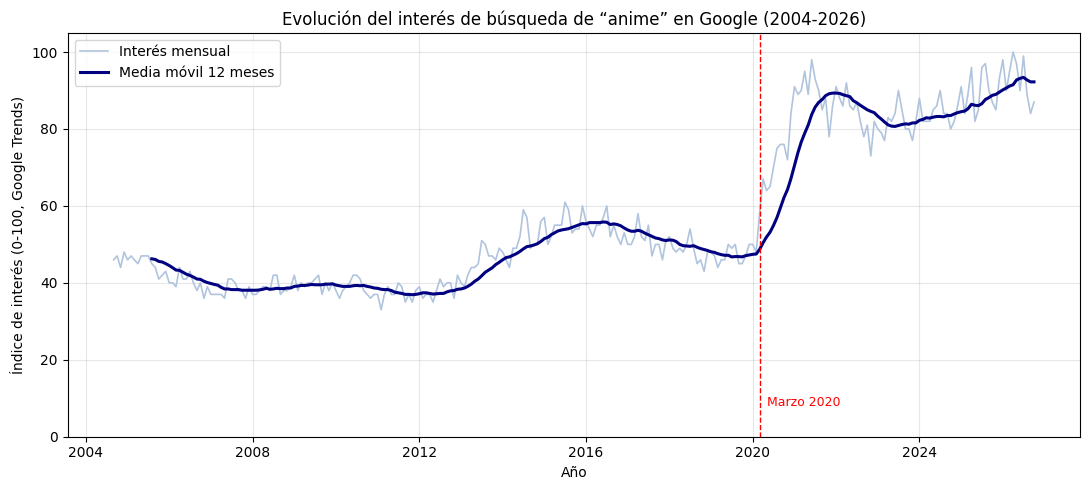

In [6]:
import io
import re
import urllib.request

# 1) Cargar el CSV desde GitHub
URL = ("https://raw.githubusercontent.com/bondiolandia/"
       "TP_Laboratorio_de_M-todos_Cuantitativos_2026/main/Interes%202004-2026.csv")

# Decodificamos usando 'latin-1' para evitar errores de caracteres especiales como acentos o ñ
texto = urllib.request.urlopen(URL).read().decode("latin-1")
lineas = texto.splitlines()

# 2) Saltear los metadatos de Google Trends: la primera fila de datos empieza con un año
idx = next(i for i, l in enumerate(lineas) if re.match(r"^\s*\d{4}", l))
interes = pd.read_csv(io.StringIO("\n".join(lineas[idx - 1:]))).iloc[:, :2]
interes.columns = ["fecha", "interes"]
interes["fecha"] = pd.to_datetime(interes["fecha"], errors="coerce")
interes["interes"] = pd.to_numeric(
    interes["interes"].astype(str).str.replace("<1", "0.5"), errors="coerce"
)
interes = interes.dropna().sort_values("fecha")

# 3) Media de 12 meses para suavizar la estacionalidad
interes["media_movil_12m"] = interes["interes"].rolling(12).mean()

# 4) Gráfico de líneas
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(interes["fecha"], interes["interes"], color="lightsteelblue",
        linewidth=1.2, label="Interés mensual")
ax.plot(interes["fecha"], interes["media_movil_12m"], color="navy",
        linewidth=2.2, label="Media móvil 12 meses")
ax.axvline(pd.Timestamp("2020-03-01"), color="red", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2020-05-01"), 8, "Marzo 2020", color="red", fontsize=9)
ax.set_ylim(0, 105)
ax.set_title("Evolución del interés de búsqueda de “anime” en Google (2004-2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Índice de interés (0-100, Google Trends)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("linea_interes.png", dpi=150)
plt.show()

# **PARTE 3.3** - Transformaciones y resumen estadistico

**Transformación 1 – Limpieza de datos y conversión de tipos.**

Al revisar la información del dataset con `.info()`, observamos que las columnas *Score*, *Episodes* y *Scored By* tenían el tipo de dato `object`, ya que los valores faltantes estaban representados como `"UNKNOWN"` en lugar de `NaN`. Por este motivo, `isnull()` no identificaba estos valores como nulos y solo detectaba los faltantes de la columna *Rating*. Para solucionarlo, reemplazamos `"UNKNOWN"` por `NaN` y convertimos las columnas correspondientes a tipos numéricos. De esta manera, podemos trabajar con los datos y calcular medidas estadísticas, como el promedio y la mediana.

Asistencia de IA para el código: *"Tengo columnas numéricas que vienen como string con el valor ‘UNKNOWN’, ‘N/A’, y otros datos que no son relevantes para el análisis . Escribí código en pandas para convertirlas a NaN y pasarlas a numérico. Sin modificar el dataset original"*

In [7]:
anime = Datos.copy()   # trabajamos sobre una copia, el original queda intacto

# 1) Placeholders -> NaN
anime = anime.replace(["UNKNOWN", "Unknown", "N/A", "Not available", "?"], np.nan)

# 2) Columnas numéricas que venían como texto
for col in ["Score", "Episodes", "Scored By"]:
    anime[col] = pd.to_numeric(anime[col], errors="coerce")

print(anime[["Score", "Episodes", "Scored By"]].dtypes)
print("\nNulos reales después de la limpieza:")
print(anime[["Score", "Episodes", "Scored By", "Genres", "Studios", "Source", "Aired"]].isnull().sum())

Score        float64
Episodes     float64
Scored By    float64
dtype: object

Nulos reales después de la limpieza:
Score        10405
Episodes       756
Scored By    10405
Genres         120
Studios      12150
Source        2694
Aired          887
dtype: int64


**Transformación 2 – Creación de las columnas Año y Década.**

La columna `Aired` contiene fechas con distintos formatos. Para poder analizar si la antigüedad de un anime se relaciona con su popularidad, extraemos el primer año de estreno y lo guardamos en una nueva columna llamada `Año`. Luego, creamos `Década` para agrupar los animes por períodos y facilitar las comparaciones.

Asistencia de IA para el código: *“¿Cómo puedo extraer el primer año de una columna con fechas en distintos formatos y crear otra columna que indique la década?”*

In [8]:

# Transformación 2: Crear Año y Década

# Extraemos el primer año de estreno de cada anime
anime["Año"] = pd.to_numeric(
    anime["Aired"].astype("string").str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Agrupamos los años por década
anime["Década"] = (anime["Año"] // 10 * 10).astype("Int64")

# Comprobamos los resultados
print("Animes sin año identificable:", anime["Año"].isnull().sum())
print(anime[["Name", "Aired", "Año", "Década"]].head())


Animes sin año identificable: 887
                              Name                         Aired   Año  Década
0                     Cowboy Bebop   Apr 3, 1998 to Apr 24, 1999  1998    1990
1  Cowboy Bebop: Tengoku no Tobira                   Sep 1, 2001  2001    2000
2                           Trigun   Apr 1, 1998 to Sep 30, 1998  1998    1990
3               Witch Hunter Robin   Jul 3, 2002 to Dec 25, 2002  2002    2000
4                   Bouken Ou Beet  Sep 30, 2004 to Sep 29, 2005  2004    2000


**Transformación 3 – Filtrado de animes sin miembros.**

Decidimos excluir los animes que no tienen calificación y que todavía no se estrenaron ya que no cuentan con miembros registrados y esto podría afectar el análisis de su popularidad.

Asistencia de IA: *“¿Cómo puedo filtrar los animes sin puntuación de ninguna persona o que todavía no se estrenaron?“*

In [9]:

# Transformación 3: Filtrar animes

antes = len(anime)

# Excluimos los animes sin calificación y los que todavía no se estrenaron
anime = anime[
    (anime["Score"] > 0) &
    (anime["Status"] != "Not yet aired")
].copy()

print(f"Filas antes: {antes:,}")
print(f"Filas después: {len(anime):,}")
print(f"Filas descartadas: {antes - len(anime):,}")

# Comparamos el promedio y la mediana de Score
print("\nScore - promedio:", round(anime["Score"].mean()),
      "| mediana:", anime["Score"].median())


Filas antes: 30,763
Filas después: 20,358
Filas descartadas: 10,405

Score - promedio: 6 | mediana: 6.39


**Transformación 4 - Eliminamos columnas que no necesitamos**

Eliminamos las columnas que no aportaban información directa a nuestra pregunta de análisis, como los nombres alternativos, las sinopsis y los enlaces a imágenes. También quitamos algunas variables redundantes o con muchos valores faltantes. Conservamos las características que podrían ayudarnos a estudiar la relación entre los atributos de un anime y su popularidad, como el género, el estudio de animación, el tipo, la puntuación y la cantidad de usuarios que calificaron los animes.

In [10]:

# Eliminamos columnas que no vamos a utilizar en el análisis
columnas_eliminar = [
    "anime_id",
    "English name",
    "Other name",
    "Synopsis",
    "Image URL",
    "Premiered",
    "Members",
    "Scored By"
]

anime = anime.drop(columns=columnas_eliminar)

print("Columnas restantes:", len(anime.columns))
print(anime.columns.tolist())



Columnas restantes: 18
['Name', 'Score', 'Genres', 'Type', 'Episodes', 'Aired', 'Status', 'Producers', 'Licensors', 'Studios', 'Source', 'Duration', 'Rating', 'Rank', 'Popularity', 'Favorites', 'Año', 'Década']


In [11]:
columnas = anime.columns.tolist()

#Uso de ia para filtrar lo que mas se repite en cada columna.
for col in columnas:
  print(f"Conteo para {col}")

  print(anime[col].value_counts().head()) #Codigo para contabilizar lo que mas se repite, en cada columna y mostrar los 5 mas utilizados.
  print("\n")

Conteo para Name
Name
Cowboy Bebop                       1
Cowboy Bebop: Tengoku no Tobira    1
Trigun                             1
Witch Hunter Robin                 1
Bouken Ou Beet                     1
Name: count, dtype: int64


Conteo para Score
Score
6.27    109
6.42    106
6.54    105
6.73    104
6.33    103
Name: count, dtype: int64


Conteo para Genres
Genres
Music          1434
Hentai         1234
Comedy          623
Music, Kids     397
Avant Garde     253
Name: count, dtype: int64


Conteo para Type
Type
TV       5480
OVA      3612
Movie    3061
Music    2710
ONA      2682
Name: count, dtype: int64


Conteo para Episodes
Episodes
1.0     9845
12.0    2316
2.0     1543
13.0     950
3.0      675
Name: count, dtype: int64


Conteo para Aired
Aired
2012    36
2009    35
2008    33
2011    32
2004    31
Name: count, dtype: int64


Conteo para Status
Status
Finished Airing     20179
Currently Airing      179
Name: count, dtype: int64


Conteo para Producers
Producers
NHK        

# **PARTE 3.4** - Análisis gráfico

Primero, reforzamos nuestro argumento incluyendo un dataset con datos sobre el crecimiento del mercado en las ultimas decadas.  Buscamos la relacion entre las ventas de animes en el mundo por año


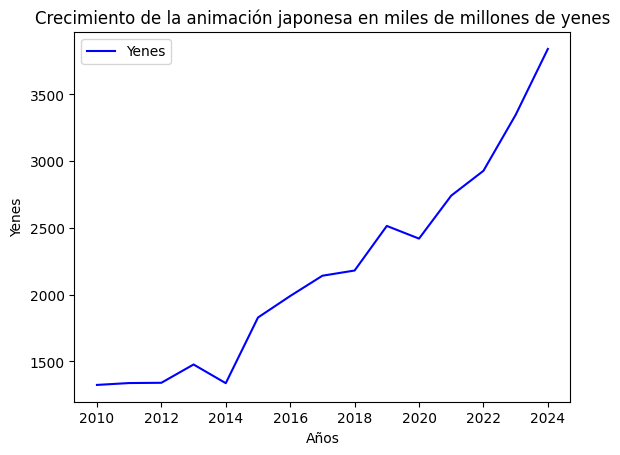

In [12]:
anime_crecimiento_en_yenes =(
    "https://raw.githubusercontent.com/bondiolandia/"
    "TP_Laboratorio_de_M-todos_Cuantitativos_2026/main/"
    "El%20mercado%20de%20la%20animaci%C3%B3n%20japonesa%20desde%202007(en%20miles%20de%20millones%20de%20yenes).xlsx"
)
anime_crecimiento_en_yenes = pd.read_excel(anime_crecimiento_en_yenes)
anime_crecimiento_en_yenes.plot (x="Años" , y="Yenes" , color="blue")    #armo el grafico
plt.title("Crecimiento de la animación japonesa en miles de millones de yenes")
plt.xlabel("Años")
plt.ylabel("Yenes")
plt.savefig("crecimiento_yenes.png", dpi=150)
plt.show()

**Resumen estadistico según el tipo de anime** – Queremos investigar si la popularidad cambia por el tipo de producción (groupby).

In [13]:
resumen_tipo = anime.groupby("Type").agg(
    Cantidad=("Score", "count"),
    Media_Score=("Score", "mean"),
    Mediana_Score=("Score", "median"),
    Q1_Score=("Score", lambda x: x.quantile(0.25)),
    Q3_Score=("Score", lambda x: x.quantile(0.75)),
    Desviacion_Estandar_Score=("Score", "std")
)

# El rango intercuartílico representa la amplitud del 50 % central de las puntuaciones
resumen_tipo["RIC_Score"] = resumen_tipo["Q3_Score"] - resumen_tipo["Q1_Score"]
resumen_tipo = resumen_tipo.sort_values("Mediana_Score", ascending=False)

display(resumen_tipo.round(2))



,Cantidad,Media_Score,Mediana_Score,Q1_Score,Q3_Score,Desviacion_Estandar_Score,RIC_Score
Type,,,,,,,
TV,5480,6.87,6.88,6.35,7.40,0.80,1.05
TV Special,629,6.49,6.44,6.01,6.94,0.75,0.93
Special,1533,6.39,6.40,5.87,6.89,0.73,1.02
Movie,3061,6.37,6.36,5.60,7.20,1.06,1.60
OVA,3612,6.28,6.28,5.73,6.81,0.79,1.08
ONA,2682,6.27,6.24,5.67,6.87,0.90,1.20
PV,245,6.08,5.98,5.59,6.53,0.73,0.94
Music,2710,5.97,5.97,5.51,6.37,0.65,0.86
CM,405,5.68,5.63,5.31,6.02,0.57,0.71


**Veamoslo de forma gráfica**


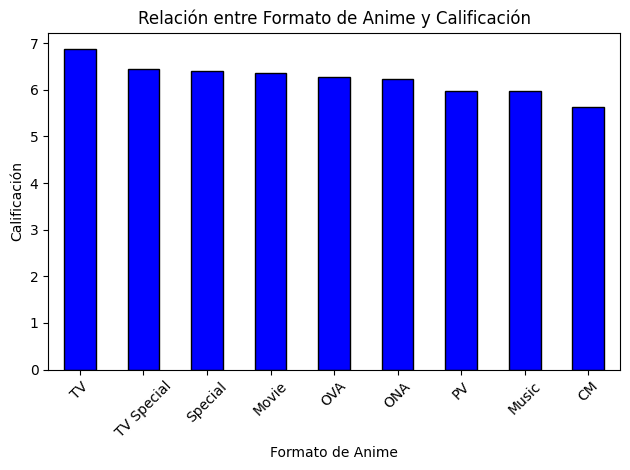

En el gráfico se muestra como los animes que son en formato TV y TV especial son los que mejor calificados están, pero los demas no se quedan atrás.


In [14]:
mediana_por_tipo = resumen_tipo["Mediana_Score"]  # ya calculada y ordenada en resumen_tipo
mediana_por_tipo.plot(kind="bar", color="blue", edgecolor="black") #Codigo para hacer el gráfico, en forma de puntitos, mientras más acumulación de animes haya, más profundose hace el color azu.
plt.title("Relación entre Formato de Anime y Calificación")
plt.xlabel("Formato de Anime")
plt.ylabel("Calificación")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("relacion_formato_calificacion.png", dpi=150)
plt.show()
print(f"En el gráfico se muestra como los animes que son en formato TV y TV especial son los que mejor calificados están, pero los demas no se quedan atrás.")

**Interpretación**: Observamos que los animes de TV presenta la puntuación media más elevada (6,87). En cambio, los musicales tienen una media de (5.97) lo que indica una posición menos favorable en el ranking. En TV, el 50 % central de las puntuaciones se encuentra aproximadamente entre 6,35 (Q1) y 7,40 (Q3), con un RIC de 1,05. En las películas, ese intervalo va de 5,60 a 7,20 y el RIC es mayor (1,60), lo que muestra una dispersión más amplia en el 50 % central. Por lo tanto, las películas presentan puntuaciones más variadas, mientras que las de TV están más concentradas. Estos resultados sugieren que existen diferencias de popularidad según el tipo de anime, aunque no permiten afirmar que el tipo sea la causa de esas diferencias.

**Resumen estadistico según el tipo de fuente original** – Podriamos preguntarnos si la popularidad depende si el anime tiene fuente original o porque son adaptaciones a mangas u otras fuentes que ya tenian más público.

In [15]:
resumen_source = anime.groupby("Source").agg(
    Cantidad=("Score", "count"),
    Media_Score=("Score", "mean"),
    Mediana_Score=("Score", "median"),
    Q1_Score=("Score", lambda x: x.quantile(0.25)),
    Q3_Score=("Score", lambda x: x.quantile(0.75)),
    Desviacion_Estandar_Score=("Score", "std")
)

resumen_source["RIC_Score"] = resumen_source["Q3_Score"] - resumen_source["Q1_Score"]
resumen_source = resumen_source.sort_values("Mediana_Score", ascending=False)

display(resumen_source.round(2))

,Cantidad,Media_Score,Mediana_Score,Q1_Score,Q3_Score,Desviacion_Estandar_Score,RIC_Score
Source,,,,,,,
Web novel,336,7.22,7.28,6.73,7.64,0.63,0.91
Light novel,1185,6.92,6.93,6.44,7.38,0.72,0.94
Manga,5293,6.84,6.85,6.28,7.41,0.83,1.13
Web manga,584,6.73,6.73,6.19,7.28,0.81,1.09
Novel,560,6.67,6.62,6.16,7.23,0.82,1.07
4-koma manga,321,6.65,6.62,6.08,7.22,0.75,1.14
Card game,76,6.40,6.51,5.95,6.76,0.53,0.81
Mixed media,209,6.52,6.47,6.09,6.96,0.68,0.87
Book,130,6.37,6.39,5.81,6.91,0.74,1.10


**Veamoslo de forma gráfica**

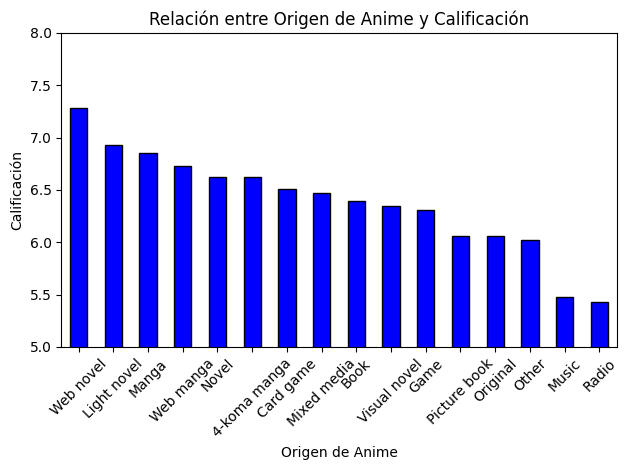

En el gráfico se muestra como los animes que son en formato TV y TV especial son los que mejor calificados están, pero los demas no se quedan atrás.


In [16]:
mediana_por_origen = resumen_source["Mediana_Score"]  # ya calculada y ordenada en resumen_source
mediana_por_origen.plot(kind="bar", color="blue", edgecolor="black") #Codigo para hacer el gráfico, en forma de puntitos, mientras más acumulación de animes haya, más profundose hace el color azu.
plt.title("Relación entre Origen de Anime y Calificación")
plt.xlabel("Origen de Anime")
plt.ylabel("Calificación")
plt.ylim(5, 8) # Establecemos que el eje Y comience en 5 para resaltar las diferencias
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("relacion_origen_calificacion.png", dpi=150)
plt.show()
print(f"En el gráfico se muestra como los animes que son en formato TV y TV especial son los que mejor calificados están, pero los demas no se quedan atrás.")

**Interpretación:** Dado este análisis se observa que los anime adaptados de "Web novel" tienen mucha más puntuación y público que otras fuentes. Si lo comparamos con animes con fuente original la diferencia es demasiada ya que esta fuente roza los últimos lugares con menos popularidad y menos puntuación. Por lo que podriamos decir que las adaptaciones de novelas web tienen la posibilidad de ser más populares que las originales.

**Resumen estadistico según el género del anime** – Decidimos agrupar los animes según su género porque queríamos investigar si existen diferencias de popularidad entre ellos. Consideramos que las preferencias de los espectadores por determinados géneros podrían estar relacionadas con la cantidad de personas que siguen un anime, su puntuación y su posición en el ranking de popularidad. De esta manera, podemos comparar los géneros e identificar posibles tendencias en los datos.

Asistencia de IA: *“Cómo agrupo por género si la columna tiene varios géneros separados por coma.*”. Se usó este prompt porque se encontró que varios animes tienen varios géneros. Asi que decidimos armar una fila con cada genero e incluir los animes para mayor organización.

In [17]:
# Separamos los géneros y creamos una fila por cada género de cada anime
generos = anime.assign(
    Genres=anime["Genres"].str.split(", ")
).explode("Genres")

# Calculamos estadísticas de Score por género.
# "count" cuenta solo los animes que tienen Score disponible.
resumen_generos = generos.dropna(subset=["Genres"]).groupby("Genres").agg(
    Cantidad=("Score", "count"),
    Media_Score=("Score", "mean"),
    Mediana_Score=("Score", "median"),
    Q1_Score=("Score", lambda x: x.quantile(0.25)),
    Q3_Score=("Score", lambda x: x.quantile(0.75)),
    Desviacion_Estandar_Score=("Score", "std")
)

resumen_generos["RIC_Score"] = resumen_generos["Q3_Score"] - resumen_generos["Q1_Score"]
resumen_generos = resumen_generos.sort_values("Mediana_Score", ascending=False)

display(resumen_generos.round(2))

,Cantidad,Media_Score,Mediana_Score,Q1_Score,Q3_Score,Desviacion_Estandar_Score,RIC_Score
Genres,,,,,,,
Award Winning,233,7.32,7.54,6.59,8.09,1.01,1.50
Iyashikei,174,7.44,7.52,6.96,7.90,0.72,0.95
Love Status Quo,44,7.27,7.37,6.62,7.64,0.62,1.02
Childcare,69,7.21,7.31,6.67,7.84,0.82,1.17
Urban Fantasy,207,7.21,7.27,6.78,7.66,0.65,0.88
...,...,...,...,...,...,...,...
Parody,702,6.28,6.18,5.55,6.92,0.96,1.37
Music,3650,6.04,6.01,5.51,6.47,0.77,0.96
Erotica,79,6.02,5.98,5.51,6.54,0.70,1.03


**Veamoslo de forma gráfica**

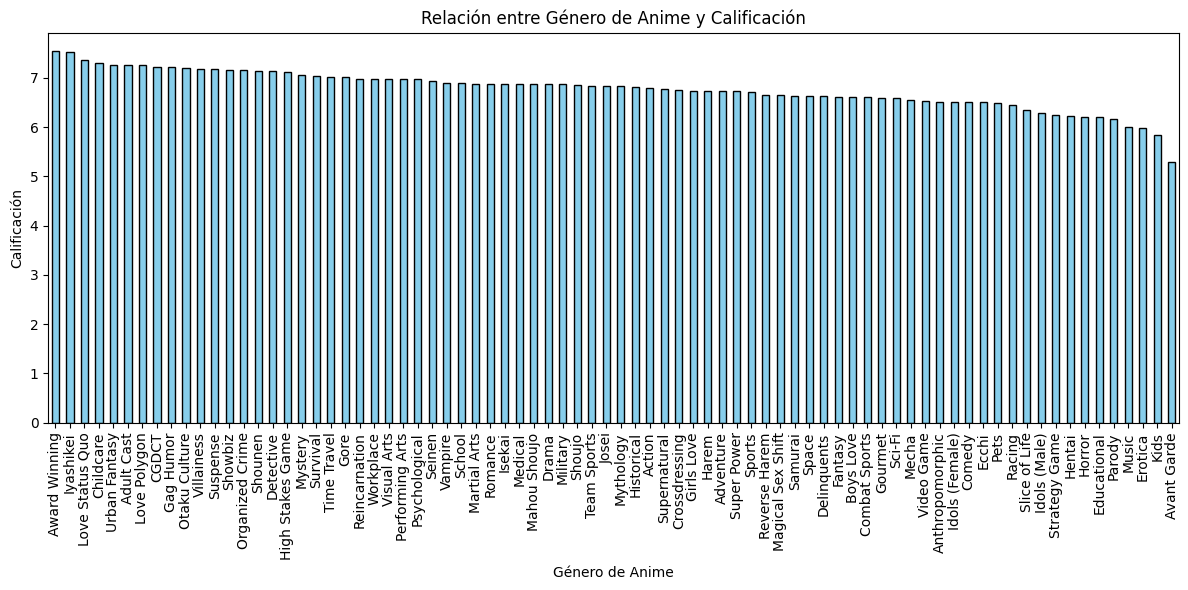

In [18]:
mediana_por_género = resumen_generos["Mediana_Score"]  # ya calculada y ordenada en resumen_generos
plt.figure(figsize=(12, 6))
mediana_por_género.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Relación entre Género de Anime y Calificación")
plt.xlabel("Género de Anime")
plt.ylabel("Calificación")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("relacion_genero_calificacion.png", dpi=150)
plt.show()

**Interpretación:** De esta tabla podemos concluir que "Award Winning" tiene la mediana de calificación más alta, con (7,54) puntos. En cambio, "Avant Garde" presenta la mediana más baja, con (5,29) puntos. Esto muestra que las calificaciones y la popularidad varían según el género.

Sin embargo, no podríamos considerar "Award winning" (en español "Galardonada") como un género comparable con el Romantico, la Comedia, etcétera. Aquella categoria engloba en todo caso a los animes que han recibido grandes reconocimientos, lo que probablemente tenga influencia en su popularidad, pero no nos sirve para aconsejar al estudio de animación. *"Creen un anime que gane un Oscar"* no sería una recomendación util.

Además, al incluir todos los generos que existen en la pagina, el grafico se hace abrumador y dificil de leer. **Intentamos con otra estrategia**.

**Veamos como influyeron los géneros en la calificación de los animes con más calificación**

/tmp/ipykernel_437/2498382402.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(x=top_generos_proporcion.index, y=top_generos_proporcion.values, palette="Blues_r")


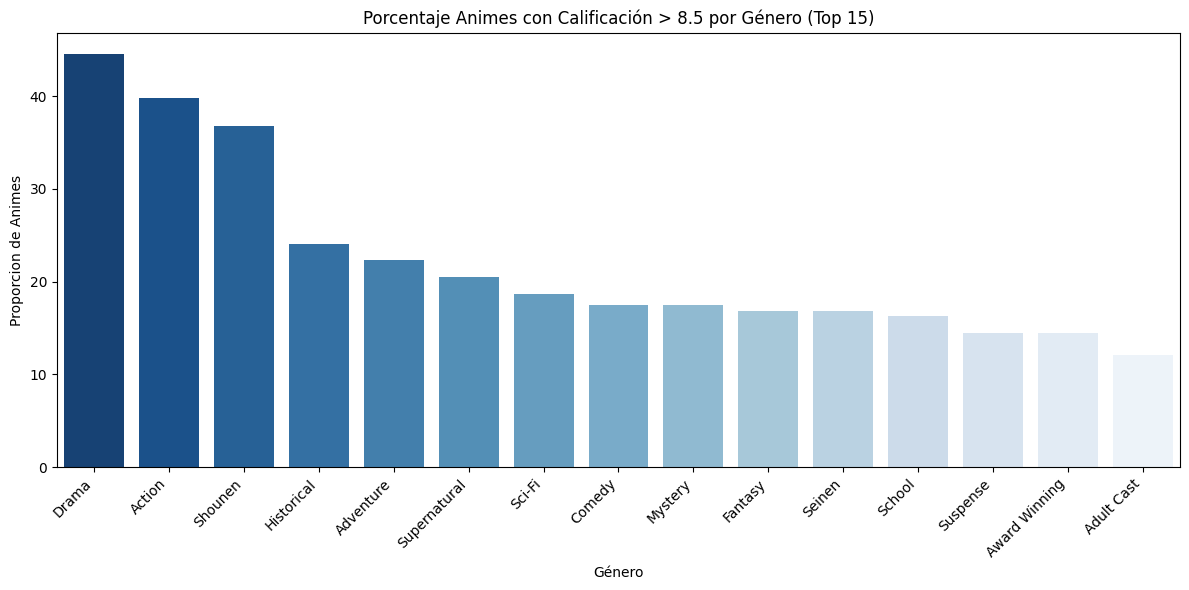

In [19]:
animes_excelentes = anime[anime["Score"] > 8.5].copy()  #filtramos por calificacion >8,5 (sobre el DF limpio `anime`, donde Score ya es numerico)

generos_df = generos[generos["Score"] > 8.5] #reutilizamos `generos` (un genero por fila, creado en la parte 3.3)
total_excelentes_unicos = len(animes_excelentes)        # Definimos explícitamente el total de animes únicos para la proporción

top_generos = generos_df["Genres"].value_counts().head(15) #Los contamos
top_generos_proporcion = (top_generos / total_excelentes_unicos) * 100 #hacemos la proporcion

plt.figure(figsize=(12, 6)) #graficamos
sb.barplot(x=top_generos_proporcion.index, y=top_generos_proporcion.values, palette="Blues_r")

plt.title("Porcentaje Animes con Calificación > 8.5 por Género (Top 15)")
plt.xlabel("Género")
plt.ylabel("Proporcion de Animes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("Calificacion_por_genero.png", dpi=150)
plt.show()

**Interpretación:** Con este grafico podemos ver claramente que los generos "Drama", "Accion" y "Shounen" concentran gran parte de los animes con puntuaciones altas.

Cabe decir que las proporciones se calculan con animes que no tienen un unico genero, y por tanto, la suma de todas las barras supera por mucho el 100%. No podemos decir algo como "El 40% de los animes con scores altos es de Accion". **Pero sí podemos interpretar que el 44.6% de todos los animes excelentes (calificación > 8.5) tienen el género Drama dentro de sus categorías; y el 39.8% de ellos contienen el género Acción.**

**Analizamos si el momento en que se estrenó tiene influencia en el puntaje obtenido.**

El prompt utilizado fue:


```
Quiero plotear una serie de graficos que dialogen con la transformacion de la parte 3.3 correspondiente a los Años, en base a nuestra pregunta de investigacion. Crea un bloque de codigo para armar un mapa de calor, con rank en el eje y y los años en el eje x.
```



Animes en el gráfico: 14,548 (se excluyen los que no tienen Rank o año)


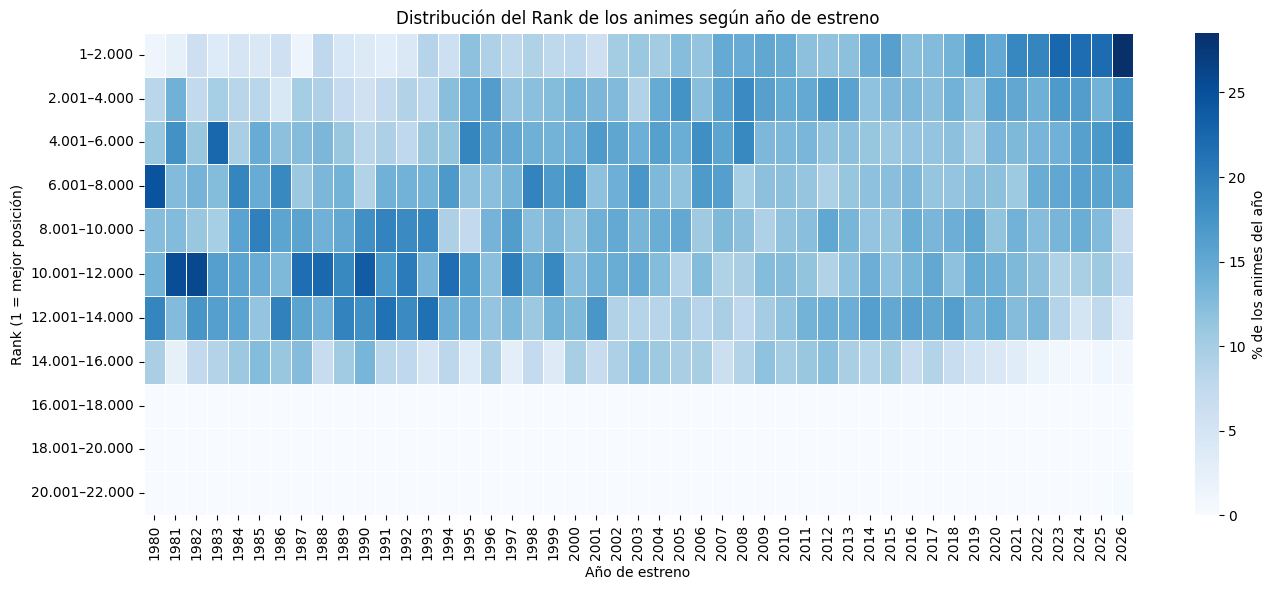

In [20]:
COL = "Rank"
ANIO_DESDE = 1980       # antes de esta fecha hay muy pocos animes por año
TAM_BIN = 2000          # amplitud de cada tramo del ranking
NORMALIZAR = True       # True: % de los animes de cada año | False: cantidad absoluta

d = anime[["Año", COL]].copy()
d[COL] = pd.to_numeric(d[COL], errors="coerce")
d = d[(d[COL] > 0) & d["Año"].between(ANIO_DESDE, 2026)].dropna()
d["Año"] = d["Año"].astype(int)
print(f"Animes en el gráfico: {len(d):,} (se excluyen los que no tienen {COL} o año)")

bordes = list(range(0, int(d[COL].max()) + TAM_BIN, TAM_BIN))
etiquetas = [f"{a + 1:,}–{b:,}".replace(",", ".") for a, b in zip(bordes[:-1], bordes[1:])]
d["Tramo"] = pd.cut(d[COL], bins=bordes, labels=etiquetas)

tabla = pd.crosstab(d["Tramo"], d["Año"])          # filas: tramo de ranking, columnas: año
tabla = tabla.reindex(etiquetas, fill_value=0)     # conserva los tramos vacíos para no deformar el eje
if NORMALIZAR:
    tabla = tabla.div(tabla.sum(axis=0), axis=1) * 100

fig, ax = plt.subplots(figsize=(14, 6))
sb.heatmap(tabla, cmap="Blues", linewidths=0.5, linecolor="white", ax=ax,
           cbar_kws={"label": "% de los animes del año" if NORMALIZAR else "Cantidad de animes"})
ax.set_title(f"Distribución del {COL} de los animes según año de estreno")
ax.set_xlabel("Año de estreno")
ax.set_ylabel(f"{COL} (1 = mejor posición)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig("mapa_calor_rank_anio.png", dpi=150)
plt.show()

**Interpretación:**  En este grafico podemos ver que los animes con mejor posicion en el ranking se concentran en la esquina superior derecha. Son los animes estrenados de 2021 en adelante. Por otro lado, los calificados de mitad del rankin (puesto 10.000) para abajo, concentran a aquellos que se estrenaron de 1994 hacia atrás.

Esto no necesariamente nos habla de que el público valore más a los animes estrenados en los ultimos 6 años, si no que podría ser una consecuencia del incremento en el interes que el animé está despertando entre el público general. Por otro lado, los animes más recientes tienen menos votos, con lo cual su rankeo puede no ser representativo del interes general que despierta.






**Veamos como afecta el licenciante en la valoración**

In [21]:
# Separamos los licenciantes y creamos una fila por cada uno de cada anime
licensors = anime.assign(
    Licensors=anime["Licensors"].str.split(", ")
).explode("Licensors")

# Calculamos estadísticas de Score por licenciante.
# "count" cuenta solo los animes que tienen Score disponible.
resumen_licensors = licensors.dropna(subset=["Licensors"]).groupby("Licensors").agg(
    Cantidad=("Score", "count"),
    Media_Score=("Score", "mean"),
    Mediana_Score=("Score", "median"),
    Q1_Score=("Score", lambda x: x.quantile(0.25)),
    Q3_Score=("Score", lambda x: x.quantile(0.75)),
    Desviacion_Estandar_Score=("Score", "std")
)

resumen_licensors["RIC_Score"] = resumen_licensors["Q3_Score"] - resumen_licensors["Q1_Score"]
resumen_licensors = resumen_licensors.sort_values("Mediana_Score", ascending=False)

display(resumen_licensors.round(2))

,Cantidad,Media_Score,Mediana_Score,Q1_Score,Q3_Score,Desviacion_Estandar_Score,RIC_Score
Licensors,,,,,,,
DreamWorks,1,8.25,8.25,8.25,8.25,NaN,0.00
Netflix,1,8.18,8.18,8.18,8.18,NaN,0.00
Pied Piper,2,8.01,8.01,7.98,8.04,0.08,0.06
Disney Platform Distribution,17,7.83,7.97,7.30,8.25,0.67,0.95
DiC Entertainment,3,7.76,7.76,7.75,7.76,0.02,0.01
...,...,...,...,...,...,...,...
Deaf Crocodile,3,5.78,5.71,5.64,5.88,0.26,0.25
Kadokawa,1,5.68,5.68,5.68,5.68,NaN,0.00
NuTech Digital,70,5.70,5.64,5.39,6.02,0.45,0.64


**Interpretación:** Aunque licenciantes como DreamWorks, Netflix, Pied Piper tienen muy pocos animes son los que tienen las mejores valoraciones en promedio.

**Veamoslo de forma gráfica**



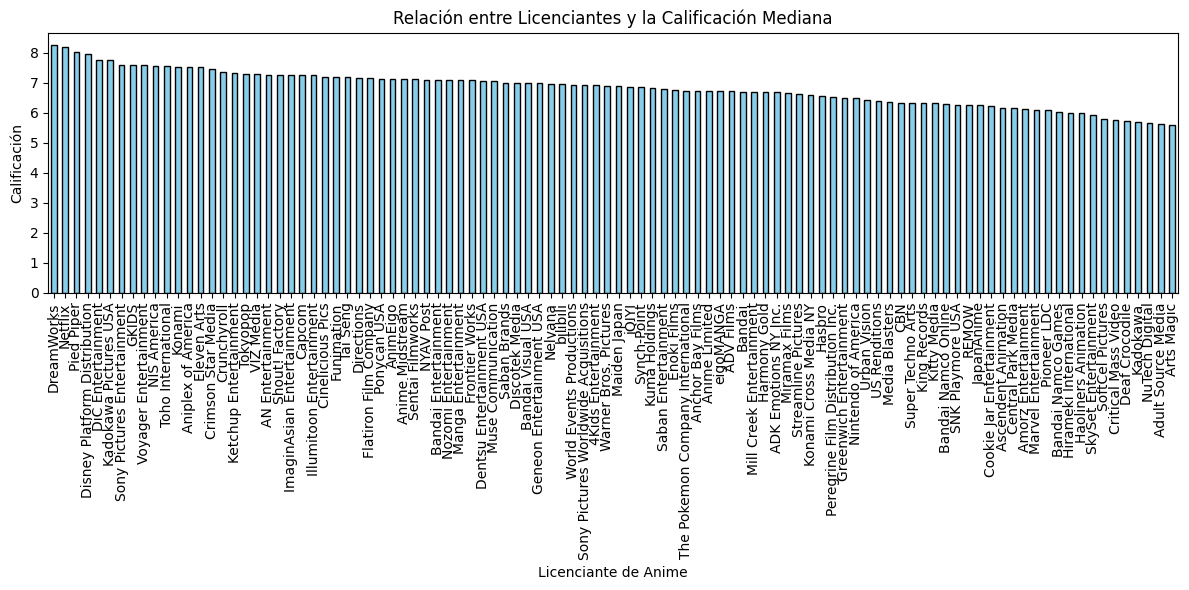

In [33]:
mediana_por_licenciantes = licensors.groupby("Licensors")["Score"].median().sort_values(ascending = False)
plt.figure(figsize=(12, 6))
mediana_por_licenciantes.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Relación entre Licenciantes y la Calificación Mediana")
plt.xlabel("Licenciante de Anime")
plt.ylabel("Calificación")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("relacion_licenciantes_calificacion_completo.png", dpi=150)
plt.show()

**Veamoslo de forma más acotada**

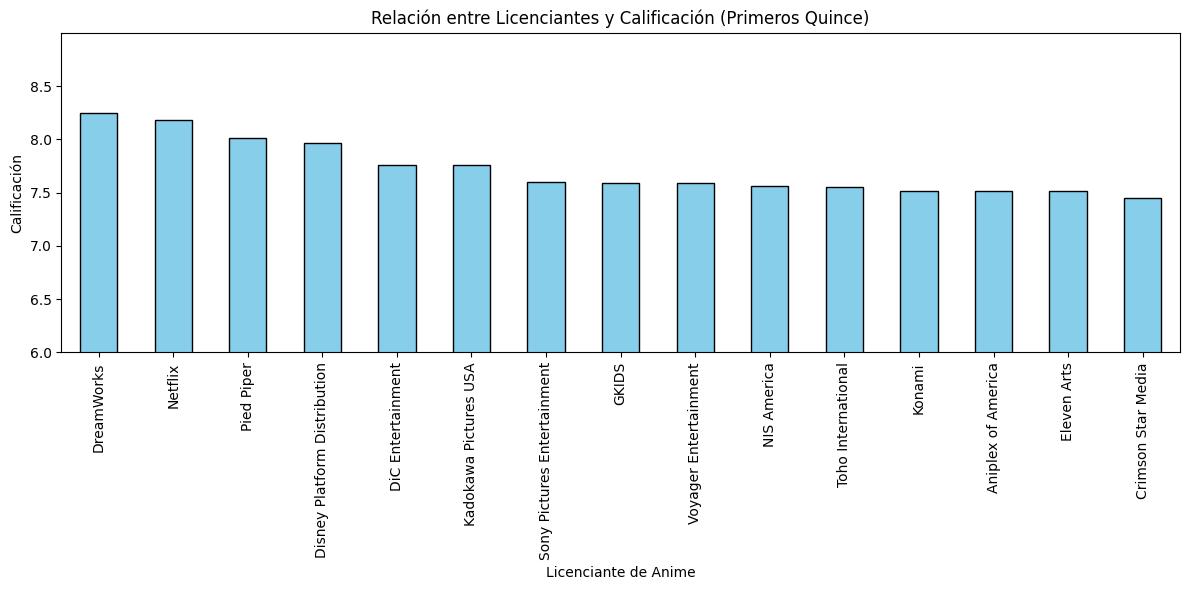

In [23]:
mediana_por_licenciantes = licensors.groupby("Licensors")["Score"].median().sort_values(ascending = False).head(15)
plt.figure(figsize=(12, 6))
mediana_por_licenciantes.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Relación entre Licenciantes y Calificación (Primeros Quince)")
plt.xlabel("Licenciante de Anime")
plt.ylabel("Calificación")
plt.xticks(rotation=90)
plt.ylim(6,9)
plt.yticks(np.arange(6.0, 9.0, 0.5))
plt.tight_layout()
plt.savefig("relacion_licenciantes_calificacion_top15.png", dpi=150)
plt.show()

**Veamos las mejores calificaciones**

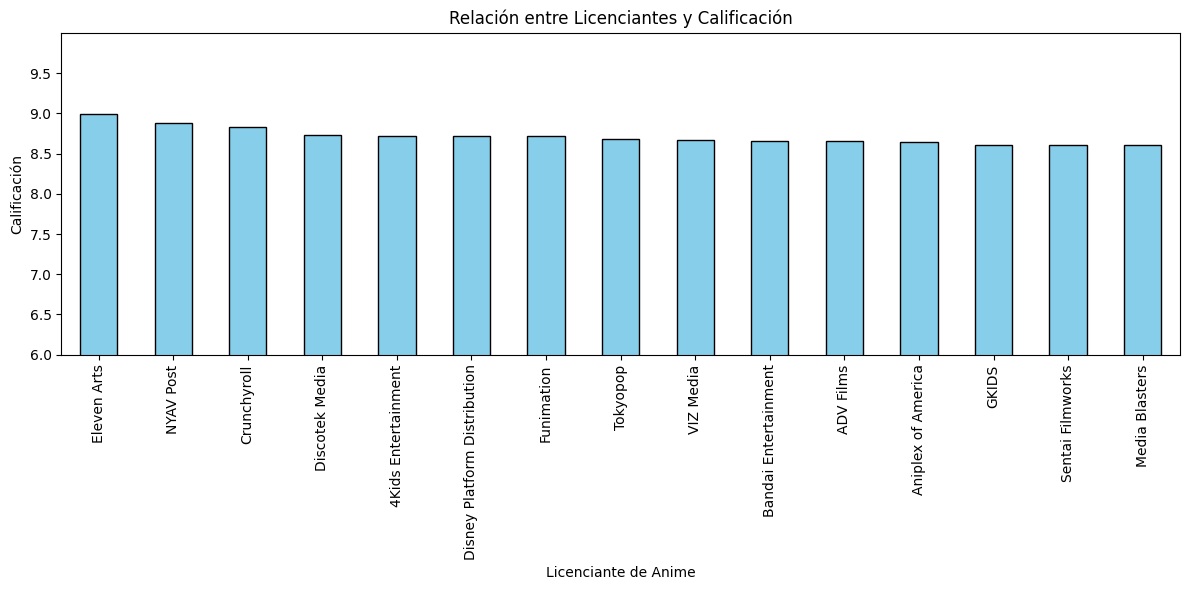

In [24]:
import seaborn as sns

anime["Score"] = pd.to_numeric(anime["Score"], errors="coerce") #aseguramos score numerico

animes_excelentes = anime[anime["Score"] > 8.5].copy()  #filtramos por calificacion >8,5

licensors_df = animes_excelentes.assign(Licensors=animes_excelentes["Licensors"].str.split(", ")).explode("Licensors") #separamos por fila para analizarlo individual

mediana_por_licenciantes = licensors_df.groupby("Licensors")["Score"].median().sort_values(ascending = False).head(15)
plt.figure(figsize=(12, 6))
mediana_por_licenciantes.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Relación entre Licenciantes y Calificación")
plt.xlabel("Licenciante de Anime")
plt.ylabel("Calificación")
plt.xticks(rotation=90)
plt.ylim(6,10)
plt.yticks(np.arange(6.0, 10.0, 0.5))
plt.tight_layout()
plt.savefig("relacion_licenciantes_excelentes.png", dpi=150)
plt.show()

**Otra Interpretación:** A diferencia del DataFrame, en estos primeros 15 licenciantes con calificaciones mayores a 8,5, se destacan licenciantes como Eleven Arts que antes estaba por los últimos aparece primero o licenciantes como Crunchyroll que antes ni llegó al anterior gráfico.

**Veamos como afecta el estudio de animación a su valoración**

In [25]:
# Separamos los estudios y creamos una fila por cada estudio de cada anime
Estudios = anime.assign(
    Studios=anime["Studios"].str.split(", ")
).explode("Studios")

# Calculamos estadísticas de Score por género.
# "count" cuenta solo los animes que tienen Score disponible.
resumen_estudios = Estudios.dropna(subset=["Studios"]).groupby("Studios").agg(
    Cantidad=("Score", "count"),
    Media_Score=("Score", "mean"),
    Mediana_Score=("Score", "median"),
    Q1_Score=("Score", lambda x: x.quantile(0.25)),
    Q3_Score=("Score", lambda x: x.quantile(0.75)),
    Desviacion_Estandar_Score=("Score", "std")
)

resumen_estudios["RIC_Score"] = resumen_estudios["Q3_Score"] - resumen_estudios["Q1_Score"]
resumen_estudios = resumen_estudios.sort_values("Mediana_Score", ascending=False)

display(resumen_estudios.round(2))

,Cantidad,Media_Score,Mediana_Score,Q1_Score,Q3_Score,Desviacion_Estandar_Score,RIC_Score
Studios,,,,,,,
Studio Signpost,7,8.08,8.66,7.53,8.72,0.88,1.19
Nippon Ramayana Film,1,8.38,8.38,8.38,8.38,NaN,0.00
Crew-Cell,1,8.31,8.31,8.31,8.31,NaN,0.00
Egg Firm,5,7.97,8.21,8.11,8.41,0.71,0.30
Sharefun Studio,7,7.83,8.20,7.72,8.26,0.77,0.54
...,...,...,...,...,...,...,...
Studio! Cucuri,2,4.12,4.12,3.74,4.50,1.09,0.77
Kigumi,1,3.79,3.79,3.79,3.79,NaN,0.00
RAMS,1,3.44,3.44,3.44,3.44,NaN,0.00


**Interpretación:** En este caso también podemos ver que los estudios que mejores calificaciones obtienen, sacan muy pocos animes.

**También veamoslo de forma más acotada**

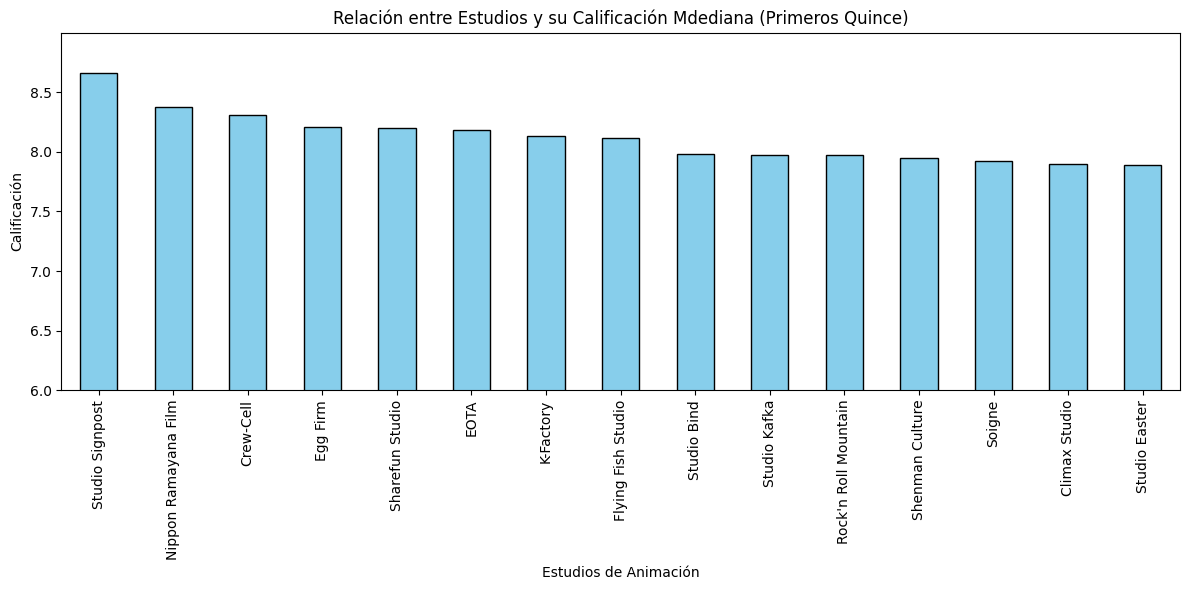

In [34]:
mediana_por_estudios = Estudios.groupby("Studios")["Score"].median().sort_values(ascending = False).head(15)
plt.figure(figsize=(12, 6))
mediana_por_estudios.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Relación entre Estudios y su Calificación Mdediana (Primeros Quince)")
plt.xlabel("Estudios de Animación")
plt.ylabel("Calificación")
plt.xticks(rotation=90)
plt.ylim(6,9)
plt.yticks(np.arange(6.0, 9.0, 0.5))
plt.tight_layout()
plt.savefig("relacion_estudios_calificacion_top15.png", dpi=150)
plt.show()

**Interpretación:** En este gráfico se pueden ver mayores diferencias entre las calificaciones, lo que podría asumirse deberse a su estudio de animación.

**Ahora veamos como se conforman los estudios con las mejores calificaciones**

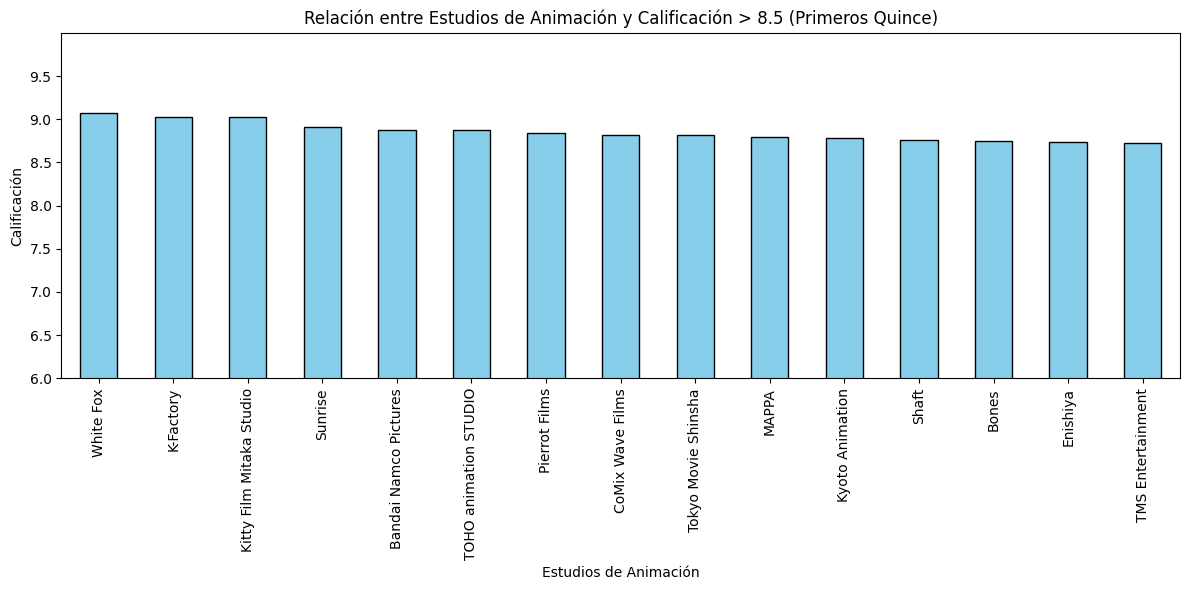

In [27]:
estudios_df = animes_excelentes.assign(Studios=animes_excelentes["Studios"].str.split(", ")).explode("Studios") #separamos por fila para analizarlo individual

mediana_por_licenciantes = estudios_df.groupby("Studios")["Score"].median().sort_values(ascending = False).head(15)
plt.figure(figsize=(12, 6))
mediana_por_licenciantes.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Relación entre Estudios de Animación y Calificación > 8.5 (Primeros Quince)")
plt.xlabel("Estudios de Animación")
plt.ylabel("Calificación")
plt.xticks(rotation=90)
plt.ylim(6,10)
plt.yticks(np.arange(6.0, 10.0, 0.5))
plt.tight_layout()
plt.savefig("relacion_estudios_excelentes_top15.png", dpi=150)
plt.show()

## Licenciantes y estudios: tres formas de mirar los mismos datos

Hasta acá ordenamos a licenciantes y estudios por la **mediana** del puntaje. Ese orden premia a los grupos con muy pocos animes: si un estudio tiene un solo anime, su mediana es el puntaje de ese anime. Por eso, en los primeros puestos aparecen grupos con 1 a 3 animes (en el filtro `Score > 8,5` además, la mediana queda entre 8,5 y 10 por construcción). Esos gráficos los dejamos como están, pero **no alcanzan para comparar** licenciantes o estudios.

Sumamos dos miradas que no tienen ese problema:

1. **Cantidad absoluta** de animes excelentes (puntaje > 8,5) de cada licenciante y estudio. Mide *volumen*: quién aparece más veces entre los mejores.
2. **Porcentaje** de animes excelentes sobre el total de animes de cada uno, exigiendo un **piso de 20 animes** para que el porcentaje no dependa de uno o dos títulos.

El prompt usado para generar esta sección fue:


```
# Analizamos los animes con puntaje mayor a 8.5 en funcion de sus distribuidoras (licenciantes) y los estudios que los crearon. Por un lado vimos la media, que da puntajes altos a firmas con pocos animes, y por otro vimos el numero total de publicaciones, que beneficia a los estudios con muchos titulos. Que otro analisis  que mejore o compemente estos dos?
```



**Cantidad absoluta: licenciantes con más animes con puntaje > 8,5**

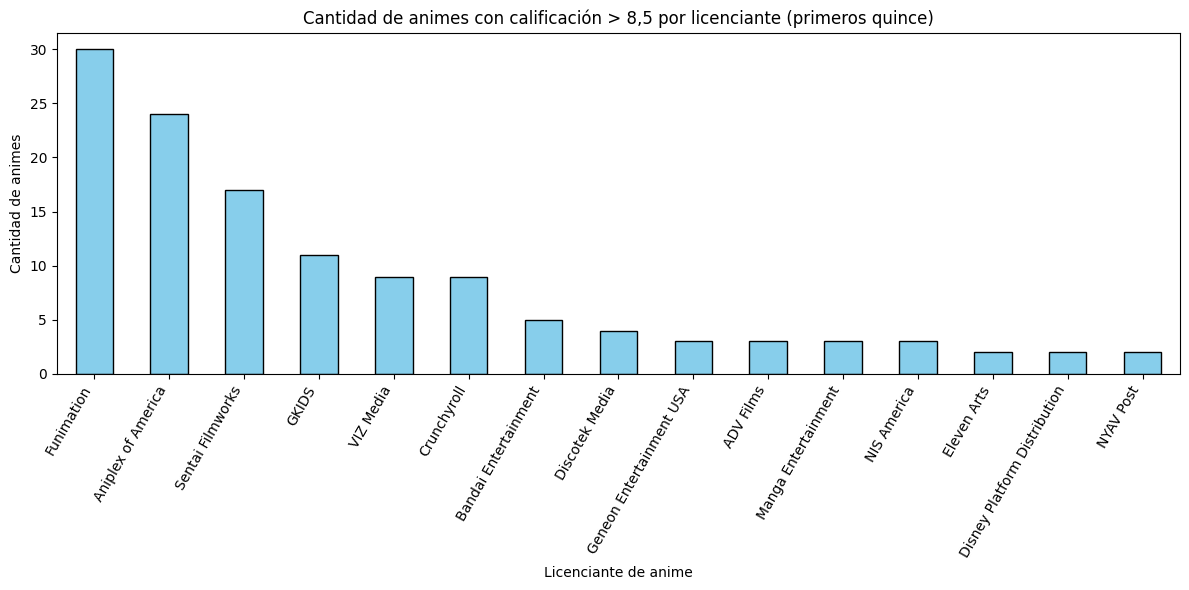

Animes excelentes con licenciante registrado: 103 de 166


In [28]:
# Animes "excelentes" (puntaje > 8,5), separando los licenciantes en una fila por cada uno
excelentes = anime[anime["Score"] > 8.5]
lic_exc = excelentes.assign(Licensors=excelentes["Licensors"].str.split(", ")).explode("Licensors")

cant_lic = lic_exc["Licensors"].value_counts().head(15)

plt.figure(figsize=(12, 6))
cant_lic.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Cantidad de animes con calificación > 8,5 por licenciante (primeros quince)")
plt.xlabel("Licenciante de anime")
plt.ylabel("Cantidad de animes")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig("cantidad_excelentes_por_licenciante.png", dpi=150)
plt.show()

print(f"Animes excelentes con licenciante registrado: {excelentes['Licensors'].notna().sum()} de {len(excelentes)}")

**Cantidad absoluta: estudios con más animes con puntaje > 8,5**

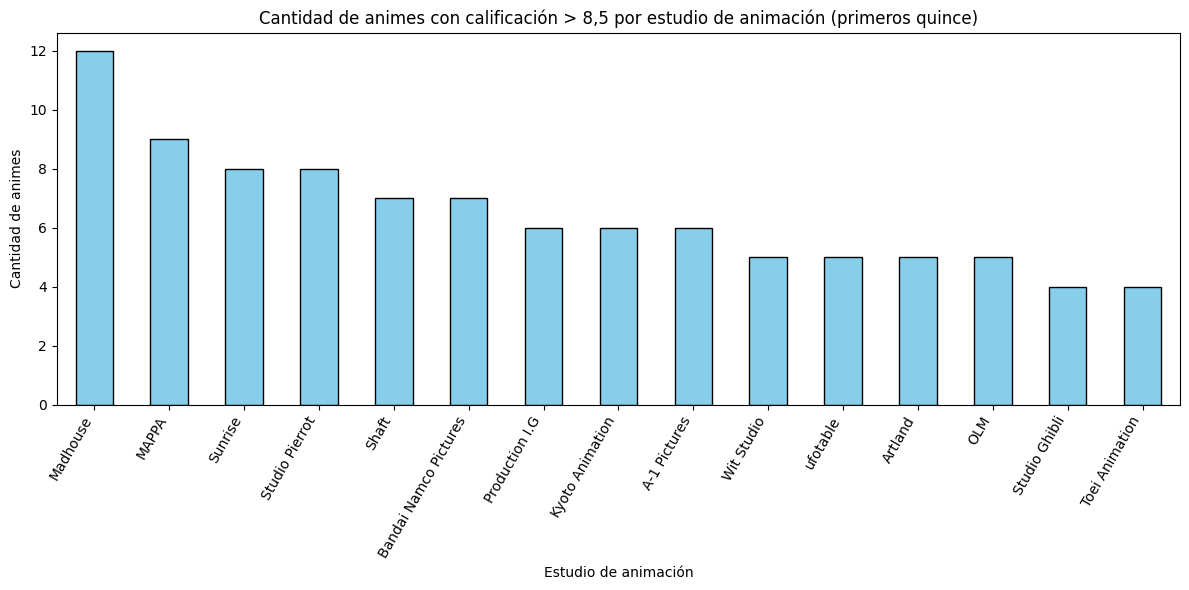

In [29]:
est_exc = excelentes.assign(Studios=excelentes["Studios"].str.split(", ")).explode("Studios")

cant_est = est_exc["Studios"].value_counts().head(15)

plt.figure(figsize=(12, 6))
cant_est.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Cantidad de animes con calificación > 8,5 por estudio de animación (primeros quince)")
plt.xlabel("Estudio de animación")
plt.ylabel("Cantidad de animes")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig("cantidad_excelentes_por_estudio.png", dpi=150)
plt.show()

**Porcentaje de animes excelentes (piso de 20 animes)**

Para cada licenciante y estudio calculamos qué porcentaje de **todos** sus animes tiene puntaje mayor a 8,5. Solo se incluyen los que tienen al menos 20 animes con puntaje, para que una sola obra no defina el resultado. La línea punteada marca el porcentaje general: el de todos los animes juntos.

Licenciantes con al menos 20 animes: 34


,Animes,Excelentes,Pct_excelentes
Licensors,,,
GKIDS,103,11,10.7
Eleven Arts,20,2,10.0
Aniplex of America,278,24,8.6
NIS America,56,3,5.4
Crunchyroll,188,9,4.8
Manga Entertainment,71,3,4.2
VIZ Media,227,9,4.0
NYAV Post,58,2,3.4
Funimation,1233,30,2.4


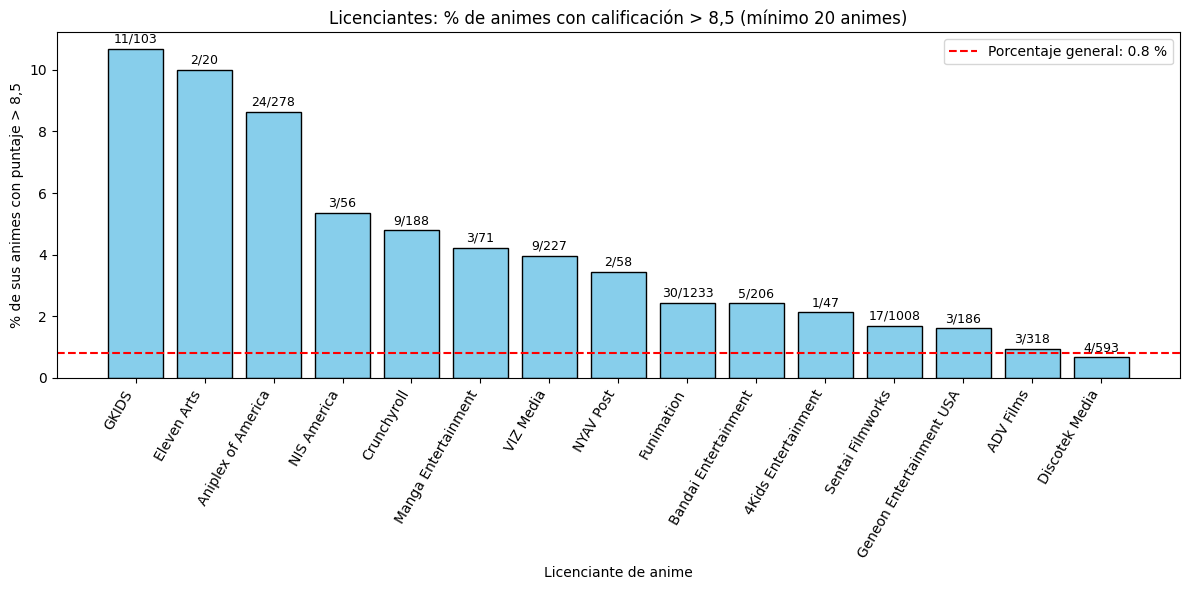

In [30]:
PISO = 20                      # mínimo de animes para que un licenciante o estudio entre en la comparación
UMBRAL = 8.5                   # puntaje a partir del cual consideramos "excelente" a un anime
pct_general = (anime["Score"] > UMBRAL).mean() * 100

def porcentaje_excelentes(df, columna, piso=PISO):
    """Una fila por cada licenciante/estudio de cada anime, y % de sus animes con Score > UMBRAL."""
    filas = df.assign(**{columna: df[columna].str.split(", ")}).explode(columna).dropna(subset=[columna])
    tabla = pd.DataFrame({
        "Animes": filas.groupby(columna).size(),
        "Excelentes": filas[filas["Score"] > UMBRAL].groupby(columna).size()
    }).fillna(0).astype(int)
    tabla["Pct_excelentes"] = tabla["Excelentes"] / tabla["Animes"] * 100
    return tabla[tabla["Animes"] >= piso].sort_values("Pct_excelentes", ascending=False)

def grafico_porcentaje(tabla, titulo, ylabel, filename):
    top = tabla.head(15)
    plt.figure(figsize=(12, 6))
    plt.bar(top.index, top["Pct_excelentes"], color="skyblue", edgecolor="black")
    for i, (nombre, fila) in enumerate(top.iterrows()):
        plt.text(i, fila["Pct_excelentes"] + 0.2, f"{int(fila['Excelentes'])}/{int(fila['Animes'])}", ha="center", fontsize=9)
    plt.axhline(pct_general, color="red", linestyle="--", label=f"Porcentaje general: {pct_general:.1f} %")
    plt.title(titulo)
    plt.xlabel(ylabel)
    plt.ylabel("% de sus animes con puntaje > 8,5")
    plt.xticks(rotation=60, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

pct_lic = porcentaje_excelentes(anime, "Licensors")
print(f"Licenciantes con al menos {PISO} animes: {len(pct_lic)}")
display(pct_lic.head(15).round(1))
grafico_porcentaje(pct_lic, f"Licenciantes: % de animes con calificación > 8,5 (mínimo {PISO} animes)", "Licenciante de anime", "porcentaje_excelentes_licenciantes.png")

**Porcentaje de animes excelentes por estudio de animación (piso de 20 animes)**

Estudios con al menos 20 animes: 166


,Animes,Excelentes,Pct_excelentes
Studios,,,
Shuka,24,4,16.7
B.CMAY PICTURES,24,3,12.5
Artland,47,5,10.6
Bandai Namco Pictures,80,7,8.8
MAPPA,111,9,8.1
Studio Ghibli,52,4,7.7
ufotable,74,5,6.8
David Production,52,3,5.8
Kinema Citrus,70,4,5.7


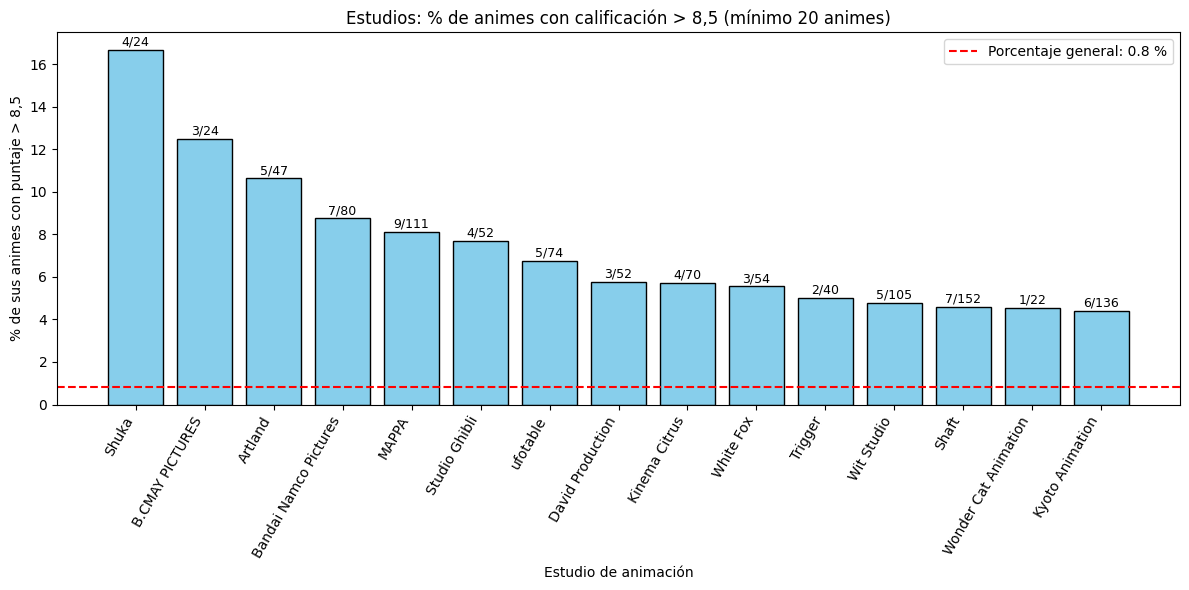

In [31]:
pct_est = porcentaje_excelentes(anime, "Studios")
print(f"Estudios con al menos {PISO} animes: {len(pct_est)}")
display(pct_est.head(15).round(1))
grafico_porcentaje(pct_est, f"Estudios: % de animes con calificación > 8,5 (mínimo {PISO} animes)", "Estudio de animación", "porcentaje_excelentes_estudios.png")

**Interpretación:** al mirar el porcentaje y no el volumen, el panorama cambia.

Este analisis nos sirve para identificar que tan probable es que un anime de determinado estudio sea calificado como Excelente, en funcion de la proporcion de animes >8.5 respecto del total de animes emitidos. Estudios como Kyoto Animation tienen muchos mas animes excelentes que estudios como Shuka, pero la proporcion respecto del total es menor.
Un dato a notar es que la condicion de score mayor a 8.5 es bastante restrictiva, y deja afuera a muchos estudios importantes: de los 166 con al menos 20 animes, 130 no tienen ningún anime con puntaje mayor a 8,5.


**Finalmente, para darle soporte a las recomendaciones que podamos hacer el base a nuestros descubrimientos hasta ahora, analizamos si existe relacion entre la valoracion que tiene un anime y su popularidad.**

El prompt utilizado fue:


```
Crea un bloque de codigo para evaluar la relacion entre Members y Score, usando un grafico de dispersión
```



Animes en el gráfico: 20,358 | coeficiente de correlacion Score–Members: 0.68


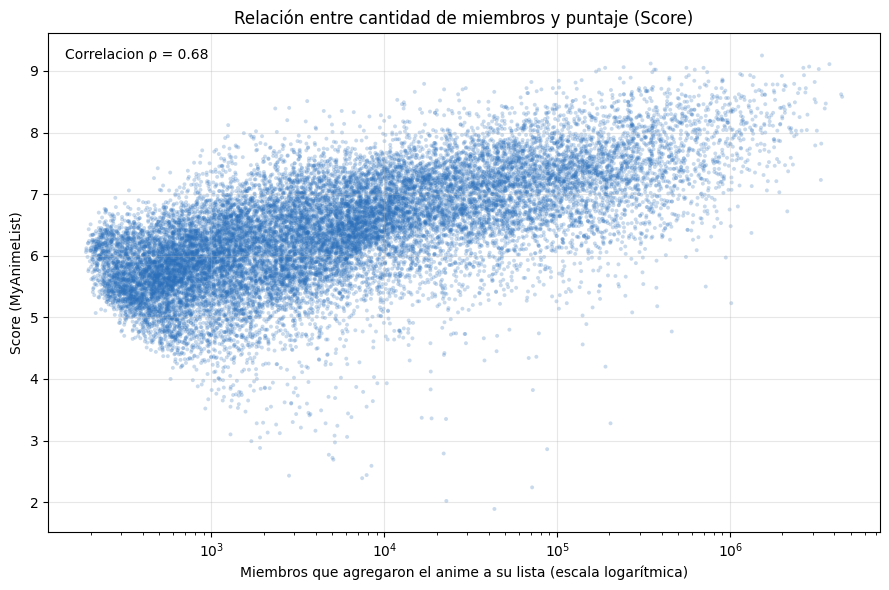

In [32]:
# Establecemos la relacion entre las dos variables: Score y Members
relacion = anime[["Score", "Popularity"]].join(Datos["Members"])
relacion = relacion[relacion["Members"] > 0]          # el eje X es logarítmico: no admite ceros

rho = relacion["Score"].corr(relacion["Members"], method="spearman")
print(f"Animes en el gráfico: {len(relacion):,} | coeficiente de correlacion Score–Members: {rho:.2f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(relacion["Members"], relacion["Score"], s=8, alpha=0.25, color="#2a6fbb", edgecolors="none")
ax.set_xscale("log")      # Members tiene cola muy larga: en escala lineal casi todo quedaría pegado al eje
ax.set_title("Relación entre cantidad de miembros y puntaje (Score)")
ax.set_xlabel("Miembros que agregaron el anime a su lista (escala logarítmica)")
ax.set_ylabel("Score (MyAnimeList)")
ax.grid(alpha=0.3)
ax.text(0.02, 0.97, f"Correlacion ρ = {rho:.2f}", transform=ax.transAxes, va="top")
plt.tight_layout()
plt.savefig("dispersion_score_members.png", dpi=150)
plt.show()

**Interpretación:** Para esta ultima observación, incluimos la columna "Members" que representa a la cantidad de usuarios de MyAnimeList que votaron por este anime (le pusieron score) o lo incluyeron en sus listas. Es decir, identifica cual es la cantidad de personas que interactuaron con éste anime, ya sea porque lo vieron o porque desean hacerlo.

Viendo la nube que dibujan los elementos y teniendo en cuenta el coeficiente de rho calculado, podemos señalar que existe una correlación moderada positiva entre ambas variables: a mayor cantidad de miembros, mayor es su valoración.

Esto por sí solo no indica causalidad, porque si bien un anime mejor valorado atrae audiencia, también es posible que un anime muy popular reciba más puntuaciones en la página.

#**¿Qué respuestas encontramos en nuestro data set?**
*   Observamos que los animes de TV presenta la puntuación media más elevada (6,87). En cambio, los musicales tienen una media de (5.97) lo que indica una posición menos favorable en el ranking. Las películas presentan puntuaciones más variadas, mientras que las de TV están más concentradas. Estos resultados sugieren que existen diferencias de popularidad según el tipo de anime, aunque no permiten afirmar que el tipo sea la causa de esas diferencias.
*   Vemos que los anime adaptados de "Web novel" tienen mucha más puntuación y público que otras fuentes. Podriamos decir que las adaptaciones de novelas web tienen la posibilidad de ser más populares que aquellas que tienen su fuente en ideas originales.
*   En cuanto la la influencia de los generos, "Drama", "Accion" y "Shounen" concentran gran parte de los animes con puntuaciones altas.
*   En base a los resultados podemos interpretar que el 44.6% de todos los animes considerados excelentes (calificación > 8.5) tienen el género Drama dentro de sus categorías; y el 39.8% de ellos contienen el género Acción.
*   Cuando analizamos el factor temporal, encontramos que los animes con mejor posicion en el ranking se concentran entre los estrenados de 2021 en adelante. Esta informacion no necesariamente nos habla de que el público valore más a los animes estrenados en los ultimos 6 años, si no que podría ser una consecuencia de que aumentó el interes que el animé está despierta entre el público general.
*   Atendiendo a la "competencia", notamos que si bien a primera vista las mejor posicionadas parecierian ser distribuidoras y estudios de animes más bien pequeñas y poco conocidas; esto se debe a que al tener 1 solo titulo y este tener una calificación alta, la mediana toma este valor. Mientras que si analizamos cuáles son las firmas que poseen mayor cantidad de títulos con valoriaciones altas, salta a la vista que son marcas de renombre como Funimation, Aniplex, MadHouse y MAPPA. Por otro lado, si analizamos cuantos represemtan los animes +8.5 respecto del total de animes que emitio cada estudio, observamos que tener muchos animes excelentes no significa que sea más probable que un anime suyo lo sea.
*   A modo de cierre, si bien no podemos afirmar que una sea causa de la otra, sí podemos afirmar existe una relación positiva entre la valoración de un anime y su popularidad, interpretada a través de la cantidad de miembros que interactuan con éste.
---

